# Acoustic Fault Diagnosis Baseline — HUSTmotor

This notebook was developed as part of a **workshop project at the Université de technologie de Compiègne (UTC)** on multimodal deep learning for electrical motor fault diagnosis using synchronized **sound and vibration signals**.

My contribution focuses on the **acoustic modality**. The goal is to build and evaluate an acoustic-only **1D CNN baseline** and study its ability to generalize across different motor operating speeds using a leave-one-speed-out protocol.

The implementation follows the CNN architecture and experimental setting described in:

> C. Zhao, W. Shen, E. Zio, and H. Ma, *“Multimodal unified generalization and translation network for intelligent fault diagnosis under dynamic environments,”* Engineering Applications of Artificial Intelligence, vol. 162, 2025, 112559.  
> DOI: https://doi.org/10.1016/j.engappai.2025.112559

Original dataset:

> [HUSTmotor Multi-Modal Dataset](https://github.com/CHAOZHAO-1/HUSTmotor-multi-modal-dataset)

Shared preprocessing used by this notebook:

> [Gentian Qinami — ISCF Project Preprocessing](https://github.com/Genti24-bit/ISCF_Project/)

The notebook covers dataset setup, domain-generalization task loading, the paper-inspired 1D CNN, training, evaluation, ten-run aggregation, and result visualization.

> **Recommended environment:** Google Colab with GPU acceleration.


In [2]:
import sys, platform, torch
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: enable a GPU in Colab.")

Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4


## 1. Mount Drive and create all folders automatically

In [3]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

# Choose which preprocessing method to test
NORM = "rms"  # Change to "zscore" for comparison

PROJECT_DIR = Path(
    "/content/drive/MyDrive/HUSTmotor_Preprocessing_Comparison"
)

DATA_DIR = PROJECT_DIR / "data"

# Separate results for each normalization method
MODELS_DIR = PROJECT_DIR / "models" / NORM
RESULTS_DIR = PROJECT_DIR / "results" / NORM
FIGURES_DIR = PROJECT_DIR / "figures" / NORM

for folder in [DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Normalization:", NORM)


Mounted at /content/drive
Project: /content/drive/MyDrive/HUSTmotor_Preprocessing_Comparison
Normalization: rms


## 2. Clone preprocessing repository

In [4]:
import subprocess, shutil
REPO_URL = "https://github.com/Genti24-bit/ISCF_Project.git"
REPO_DIR = Path("/content/ISCF_Project")

if REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)

subprocess.run(["git", "clone", "--quiet", REPO_URL, str(REPO_DIR)], check=True)

commit = subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True
).strip()

print("Repo:", REPO_DIR)
print("Commit:", commit)

Repo: /content/ISCF_Project
Commit: 7e0820c612d402a98abe554c6e6c9ddf490600c6



## 3. Download and verify the HUSTmotor dataset (v1.3)

This experiment uses the preprocessed **HUSTmotor v1.3 dataset**, provided by the shared preprocessing repository.

**Dataset file:** `hustmotor_1024_v1.3.npz`

**Release:** [ISCF Project — v1.3](https://github.com/Genti24-bit/ISCF_Project/releases/tag/v1.3)

**Expected SHA-256 checksum:**

`605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d`

### Dataset contents

The dataset contains:

- Acoustic and vibration signals, each represented by 1,024-sample windows.
- Six motor conditions and four operating speeds: 5, 10, 20 and 30 Hz.
- Domain labels and predefined training/test splits.
- Per-window RMS values and DC offsets.
- Eleven engineered time-domain features for each modality.

The v1.3 release adds the metadata needed for amplitude-preserving RMS normalization and feature analysis.

### Dataset integrity

The file is downloaded to Google Drive and verified using SHA-256 to ensure that the correct dataset version is used.

The notebook uses the shared preprocessing loader, `load_dg_task()`, to construct the domain-generalization experiments.


In [5]:
import hashlib
import requests
from tqdm.auto import tqdm

DATA_PATH = DATA_DIR / "hustmotor_1024_v1.3.npz"

EXPECTED_SHA256 = (
    "605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d"
)

def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_data(path):
    api = (
        "https://api.github.com/repos/"
        "Genti24-bit/ISCF_Project/releases/tags/v1.3"
    )

    release = requests.get(api, timeout=30)
    release.raise_for_status()

    assets = release.json()["assets"]

    asset = next(
        a for a in assets
        if a["name"] == "hustmotor_1024_v1.3.npz"
    )

    url = asset["browser_download_url"]

    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))

        with open(path, "wb") as f, tqdm(
            total=total,
            unit="B",
            unit_scale=True
        ) as bar:
            for chunk in r.iter_content(1024 * 1024):
                if chunk:
                    f.write(chunk)
                    bar.update(len(chunk))

if not DATA_PATH.exists() or file_hash(DATA_PATH) != EXPECTED_SHA256:
    print("Downloading dataset v1.3...")
    download_data(DATA_PATH)

actual = file_hash(DATA_PATH)

print("Dataset:", DATA_PATH)
print("SHA-256:", actual)

assert actual == EXPECTED_SHA256, "Dataset hash mismatch!"

print("Dataset v1.3 verified successfully!")


Dataset: /content/drive/MyDrive/HUSTmotor_Preprocessing_Comparison/data/hustmotor_1024_v1.3.npz
SHA-256: 605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d
Dataset v1.3 verified successfully!


## 4. Import the shared loader and inspect the dataset

In [6]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt

sys.path.insert(0, str(REPO_DIR))
from preprocess_hustmotor import load_dg_task

d = np.load(DATA_PATH)

for key in d.files:
    print(f"{key:10s} {d[key].shape} {d[key].dtype}")

print("Classes:", d["classes"])
print("Domains:", d["domains"])
print("Meta:", d["meta"])

vib        (24000, 1024) float32
ac         (24000, 1024) float32
y          (24000,) int8
domain     (24000,) int8
block      (24000,) int8
win        (24000,) int16
split      (24000,) int8
rms_v      (24000,) float32
rms_a      (24000,) float32
dc_v       (24000,) float32
dc_a       (24000,) float32
start      (24000,) int64
feat_v     (24000, 11) float32
feat_a     (24000, 11) float32
feat_names (11,) <U13
classes    (6,) <U6
domains    (4,) <U7
meta       (5,) <U11
Classes: ['H' 'BF' 'BOW' 'BROKEN' 'MISAL' 'UNBAL']
Domains: ['B1_5Hz' 'B2_10Hz' 'B3_20Hz' 'B4_30Hz']
Meta: ['win=1024' 'vib=X' 'norm=zscore' 'split=block' 'fs=25600']


In [7]:
import json
import platform
import sklearn
import torch
import numpy as np
import pandas as pd

experiment_metadata = {
    "experiment": "HUSTmotor_Acoustic_RMS",
    "dataset": DATA_PATH.name,
    "dataset_sha256": EXPECTED_SHA256,
    "preprocessing_repository": REPO_URL,
    "preprocessing_commit": commit,
    "normalization": NORM,
    "training_epochs": 50,
    "batch_size": 256,
    "random_seeds": list(range(10)),
    "tasks": [9, 10, 11, 12],
    "model_selection": "source validation accuracy",
    "evaluation": "leave-one-speed-out",
    "current_runtime": {
        "python": platform.python_version(),
        "pytorch": torch.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "sklearn": sklearn.__version__,
        "cuda_available": torch.cuda.is_available(),
        "cuda_version": torch.version.cuda
    }
}

metadata_path = RESULTS_DIR / "experiment_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(
        experiment_metadata,
        f,
        indent=4,
        default=str
    )

print("Saved:", metadata_path)
print(json.dumps(experiment_metadata, indent=2, default=str))

Saved: /content/drive/MyDrive/HUSTmotor_Preprocessing_Comparison/results/rms/experiment_metadata.json
{
  "experiment": "HUSTmotor_Acoustic_RMS",
  "dataset": "hustmotor_1024_v1.3.npz",
  "dataset_sha256": "605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d",
  "preprocessing_repository": "https://github.com/Genti24-bit/ISCF_Project.git",
  "preprocessing_commit": "7e0820c612d402a98abe554c6e6c9ddf490600c6",
  "normalization": "rms",
  "training_epochs": 50,
  "batch_size": 256,
  "random_seeds": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9
  ],
  "tasks": [
    9,
    10,
    11,
    12
  ],
  "model_selection": "source validation accuracy",
  "evaluation": "leave-one-speed-out",
  "current_runtime": {
    "python": "3.13.16",
    "pytorch": "2.11.0+cu130",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "sklearn": "1.6.1",
    "cuda_available": true,
    "cuda_version": "13.0"
  }
}



## 5. Load Task 9 — RMS-normalized acoustic signals

### Domain-generalization protocol

Task 9 evaluates whether a CNN trained on three motor speeds can recognize faults at an unseen speed.

| Dataset partition | Motor speeds | Acoustic windows | Purpose |
|---|---|---:|---|
| Source training | 10, 20, 30 Hz | 14,400 | Train the CNN |
| Source validation | 10, 20, 30 Hz | 3,600 | Select the best checkpoint |
| Target test | 5 Hz | 1,200 | Evaluate generalization |

The target motor speed is excluded from both training and model selection.

### RMS normalization

The dataset stores per-window z-score-normalized acoustic signals together with the original per-window RMS values.

Using `load_dg_task(..., norm="rms")`, the loader:

1. Reconstructs DC-removed signals by multiplying each stored z-score window by its original RMS.
2. Computes a single acoustic RMS scaling factor using **only the source-training windows**.
3. Divides the reconstructed acoustic signals by that source-training scale.
4. Applies the same scale to source-validation and unseen-target windows.

This removes the DC offset while preserving relative amplitude differences between windows.

The acoustic input arrays are:

- `Xa_tr`: Source-training acoustic windows
- `Xa_va`: Source-validation acoustic windows
- `Xa_te`: Unseen-target acoustic windows

**Important:** The signals must not be normalized again. The loader already applies the selected normalization consistently.

The RMS scaling factors are recorded in `t["scale"]`.


In [ ]:
TASK_TO_DOMAIN = {9: 0, 10: 1, 11: 2, 12: 3}

DOMAIN_TO_SPEED = {
    0: "5 Hz",
    1: "10 Hz",
    2: "20 Hz",
    3: "30 Hz"
}

CLASS_NAMES = [
    "Healthy",
    "Bearing fault",
    "Bowed rotor",
    "Broken rotor bars",
    "Rotor misalignment",
    "Voltage unbalance"
]

TASK = 9

t = load_dg_task(
    str(DATA_PATH),
    target_domain=TASK_TO_DOMAIN[TASK],
    norm=NORM
)

Xv_tr, Xa_tr, y_tr = t["train"]
Xv_va, Xa_va, y_va = t["val"]
Xv_te, Xa_te, y_te = t["target"]

print("Normalization:", NORM)
print("Train:", Xa_tr.shape, y_tr.shape)
print("Val:  ", Xa_va.shape, y_va.shape)
print("Test: ", Xa_te.shape, y_te.shape)

print("RMS scales (vibration, acoustic):", t["scale"])

assert Xa_tr.shape == (14400, 1024)
assert Xa_va.shape == (3600, 1024)
assert Xa_te.shape == (1200, 1024)

print("Training acoustic RMS:",
      np.sqrt(np.mean(Xa_tr ** 2)))


Normalization: rms
Train: (14400, 1024) (14400,)
Val:   (3600, 1024) (3600,)
Test:  (1200, 1024) (1200,)
RMS scales (vibration, acoustic): (0.0326678196506084, 0.01648607383634835)
Training acoustic RMS: 1.0


## 6. Inspect class balance and example acoustic windows

,class,count
0,Healthy,2400
1,Bearing fault,2400
2,Bowed rotor,2400
3,Broken rotor bars,2400
4,Rotor misalignment,2400
5,Voltage unbalance,2400


,class,count
0,Healthy,600
1,Bearing fault,600
2,Bowed rotor,600
3,Broken rotor bars,600
4,Rotor misalignment,600
5,Voltage unbalance,600


,class,count
0,Healthy,200
1,Bearing fault,200
2,Bowed rotor,200
3,Broken rotor bars,200
4,Rotor misalignment,200
5,Voltage unbalance,200


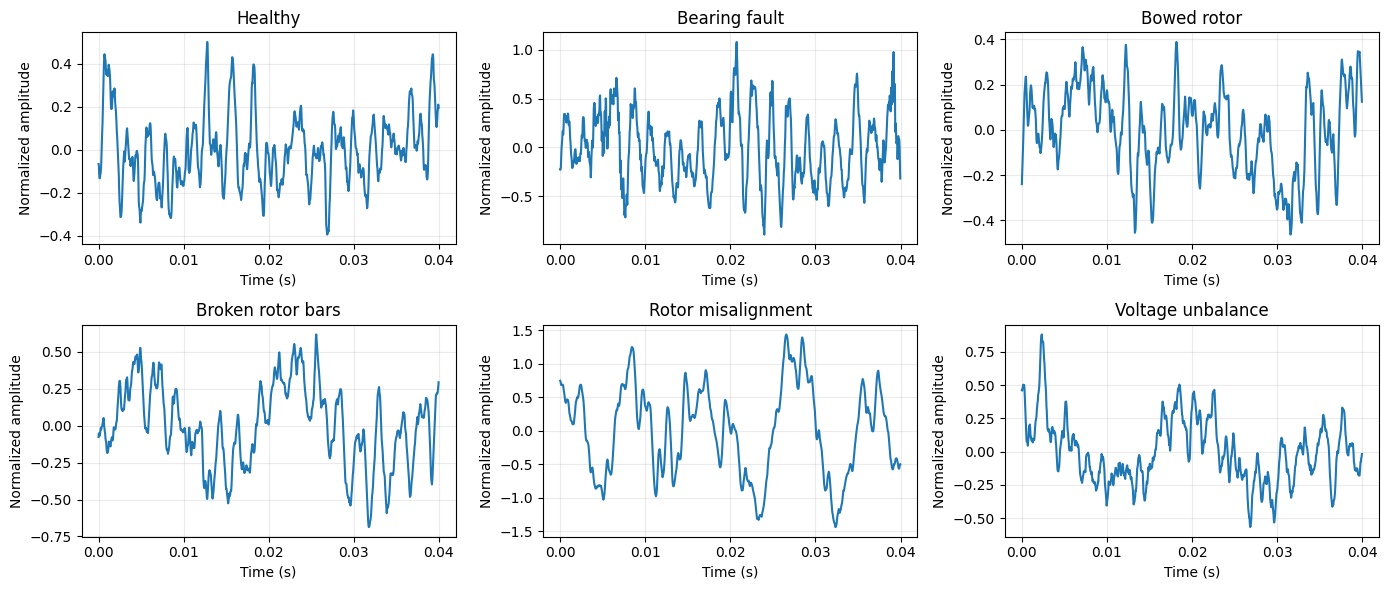

In [ ]:
def counts(y):
    return pd.DataFrame({
        "class": CLASS_NAMES,
        "count": np.bincount(y.astype(np.int64), minlength=6)
    })

display(counts(y_tr))
display(counts(y_va))
display(counts(y_te))

FS = 25_600
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for c, ax in enumerate(axes.ravel()):
    i = np.where(y_tr == c)[0][0]
    x = Xa_tr[i]
    time = np.arange(1024) / FS
    ax.plot(time, x)
    ax.set_title(CLASS_NAMES[c])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Normalized amplitude")
    ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## 7. PyTorch DataLoaders

`Conv1d` expects `(batch, channels, length)`, so `(N,1024)` becomes `(N,1,1024)`.

In [ ]:
import random
from torch.utils.data import TensorDataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 256

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def make_loader(X, y, shuffle):
    X = torch.from_numpy(X).float().unsqueeze(1)
    y = torch.from_numpy(y.astype(np.int64)).long()
    return DataLoader(
        TensorDataset(X, y),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=2,
        pin_memory=(DEVICE.type == "cuda")
    )

train_loader = make_loader(Xa_tr, y_tr, True)
val_loader = make_loader(Xa_va, y_va, False)
test_loader = make_loader(Xa_te, y_te, False)

xb, yb = next(iter(train_loader))
print("Device:", DEVICE)
print("X batch:", xb.shape)
print("y batch:", yb.shape, yb.dtype)

Device: cuda
X batch: torch.Size([256, 1, 1024])
y batch: torch.Size([256]) torch.int64


## 8. Paper-style acoustic 1D CNN

Feature extractor from Table 1:
- Conv1D 16, kernel 64 -> pool 2
- Conv1D 32, kernel 16 -> pool 2
- Conv1D 64, kernel 5 -> pool 2
- Conv1D 64, kernel 5 -> pool 2
- fully connected classifier -> 6 classes

Implementation assumptions because the paper does not specify them:
- `padding=0` (valid convolution)
- `Conv -> BatchNorm -> ReLU -> MaxPool`

We do **not** put Softmax inside `forward()` because `CrossEntropyLoss` expects logits.

In [ ]:
import torch.nn as nn

class AcousticCNN1D(nn.Module):
    def __init__(self, n_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 16, 64, stride=1, padding=0),
            nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2,2),

            nn.Conv1d(16, 32, 16, stride=1, padding=0),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2,2),

            nn.Conv1d(32, 64, 5, stride=1, padding=0),
            nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2,2),

            nn.Conv1d(64, 64, 5, stride=1, padding=0),
            nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2,2),
        )

        with torch.no_grad():
            z = self.features(torch.zeros(1,1,1024))
            self.feature_shape = tuple(z.shape[1:])
            flat_dim = z.flatten(1).shape[1]

        self.classifier = nn.Linear(flat_dim, n_classes)

    def extract_features(self, x):
        return self.features(x).flatten(1)

    def forward(self, x):
        return self.classifier(self.extract_features(x))

model = AcousticCNN1D().to(DEVICE)
print(model)
print("Feature shape:", model.feature_shape)

with torch.no_grad():
    out = model(torch.zeros(8,1,1024).to(DEVICE))
print("Output:", out.shape)
assert out.shape == (8,6)

AcousticCNN1D(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(64,), stride=(1,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(16, 32, kernel_size=(16,), stride=(1,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(32, 64, kernel_size=(5,), stride=(1,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv1d(64, 64, kernel_size=(5,), stride=(1,))
    (13): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
    (15): MaxPool1d(kernel_size=2, stride=2, padding=0, dilat

## 9. Training utilities

Paper settings:
- Adam
- 50 epochs
- batch size 256
- `lr = 0.0005 / (1 + 10*p)^0.75`
- `p = epoch / total_epochs`

Model selection uses the **source validation set only**.  
The unseen target is evaluated only after the best validation checkpoint has been chosen.

In [ ]:
from copy import deepcopy

BASE_LR = 0.0005
EPOCHS = 50

def paper_lr(epoch, total_epochs):
    p = epoch / total_epochs
    return BASE_LR / ((1 + 10*p) ** 0.75)

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    ys, ps = [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        loss = criterion(logits, y)
        pred = logits.argmax(1)

        loss_sum += loss.item() * y.size(0)
        correct += (pred == y).sum().item()
        n += y.size(0)
        ys.append(y.cpu())
        ps.append(pred.cpu())

    return {
        "loss": loss_sum/n,
        "accuracy": correct/n,
        "y_true": torch.cat(ys).numpy(),
        "y_pred": torch.cat(ps).numpy()
    }

def train_model(train_loader, val_loader, seed=0, epochs=50, verbose=True):
    set_seed(seed)
    model = AcousticCNN1D().to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=BASE_LR)

    best_acc, best_epoch, best_state = -1, -1, None
    hist = []

    for epoch in range(epochs):
        lr = paper_lr(epoch, epochs)
        for g in optimizer.param_groups:
            g["lr"] = lr

        model.train()
        loss_sum, correct, n = 0.0, 0, 0

        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += y.size(0)

        train_loss = loss_sum/n
        train_acc = correct/n
        val = evaluate(model, val_loader, criterion)

        hist.append({
            "epoch": epoch+1,
            "lr": lr,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val["loss"],
            "val_acc": val["accuracy"]
        })

        if val["accuracy"] > best_acc:
            best_acc = val["accuracy"]
            best_epoch = epoch+1
            best_state = deepcopy(model.state_dict())

        if verbose and (epoch == 0 or (epoch+1)%5 == 0 or epoch+1 == epochs):
            print(
                f"Epoch {epoch+1:02d}/{epochs} | "
                f"train={train_acc:.4f} | val={val['accuracy']:.4f} | lr={lr:.6f}"
            )

    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best_epoch, best_acc

## 10. Smoke test (2 epochs only)

In [ ]:
smoke_model, smoke_hist, _, _ = train_model(
    train_loader, val_loader, seed=0, epochs=2, verbose=True
)
display(smoke_hist)
print("Smoke test finished.")

Epoch 01/2 | train=0.4990 | val=0.6497 | lr=0.000500
Epoch 02/2 | train=0.7119 | val=0.7225 | lr=0.000130


,epoch,lr,train_loss,train_acc,val_loss,val_acc
0,1,0.00050,1.185518,0.499028,0.794079,0.649722
1,2,0.00013,0.684589,0.711944,0.644113,0.722500


Smoke test finished.


## 11. Real Task 9 experiment (50 epochs)

After training is finished and the best source-validation checkpoint is selected, we evaluate the unseen 5 Hz target **once**.

In [ ]:
TASK = 9
SEED = 0

model, history, best_epoch, best_val = train_model(
    train_loader, val_loader, seed=SEED, epochs=50, verbose=True
)

target = evaluate(model, test_loader, nn.CrossEntropyLoss())

print("\nTask 9")
print("Best source-val epoch:", best_epoch)
print(f"Best val accuracy: {100*best_val:.2f}%")
print(f"Unseen 5 Hz target accuracy: {100*target['accuracy']:.2f}%")

model_path = MODELS_DIR / f"acoustic_task{TASK}_seed{SEED}.pt"
torch.save({
    "task": TASK,
    "seed": SEED,
    "best_epoch": best_epoch,
    "best_val_acc": best_val,
    "target_acc": target["accuracy"],
    "model_state_dict": model.state_dict(),
    "dataset_sha256": EXPECTED_SHA256,
    "git_commit": commit
}, model_path)

history.to_csv(
    RESULTS_DIR / f"history_task{TASK}_seed{SEED}.csv",
    index=False
)

print("Saved:", model_path)

Epoch 01/50 | train=0.4990 | val=0.6497 | lr=0.000500
Epoch 05/50 | train=0.8820 | val=0.8642 | lr=0.000322
Epoch 10/50 | train=0.9226 | val=0.8756 | lr=0.000231
Epoch 15/50 | train=0.9401 | val=0.8886 | lr=0.000184
Epoch 20/50 | train=0.9581 | val=0.8944 | lr=0.000154
Epoch 25/50 | train=0.9649 | val=0.9019 | lr=0.000134
Epoch 30/50 | train=0.9735 | val=0.9031 | lr=0.000119
Epoch 35/50 | train=0.9733 | val=0.9064 | lr=0.000107
Epoch 40/50 | train=0.9810 | val=0.9100 | lr=0.000098
Epoch 45/50 | train=0.9860 | val=0.9144 | lr=0.000090
Epoch 50/50 | train=0.9878 | val=0.9231 | lr=0.000084

Task 9
Best source-val epoch: 50
Best val accuracy: 92.31%
Unseen 5 Hz target accuracy: 30.83%
Saved: /content/drive/MyDrive/HUSTmotor_Preprocessing_Comparison/models/rms/acoustic_task9_seed0.pt


## 12. Learning curve

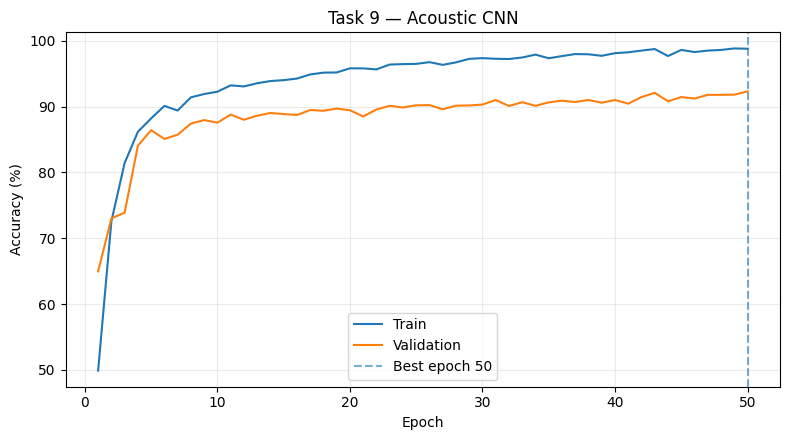

Saved: /content/drive/MyDrive/HUSTmotor_Preprocessing_Comparison/figures/rms/task9_learning_curve.png


In [ ]:
plt.figure(figsize=(8,4.5))
plt.plot(history["epoch"], 100*history["train_acc"], label="Train")
plt.plot(history["epoch"], 100*history["val_acc"], label="Validation")
plt.axvline(best_epoch, linestyle="--", alpha=.6, label=f"Best epoch {best_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Task 9 — Acoustic CNN")
plt.grid(alpha=.25)
plt.legend()
plt.tight_layout()

p = FIGURES_DIR / "task9_learning_curve.png"
plt.savefig(p, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", p)

## 13. Confusion matrix and class-wise metrics

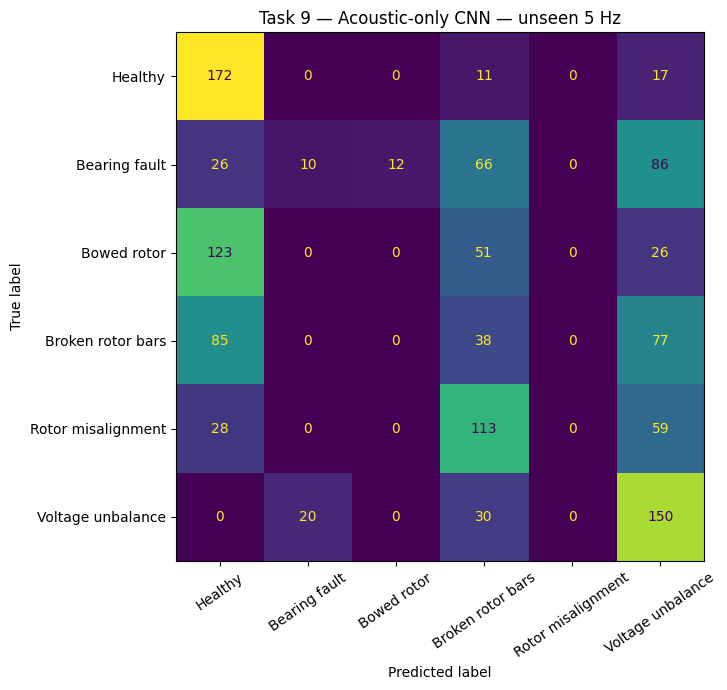

                    precision    recall  f1-score   support

           Healthy     0.3963    0.8600    0.5426       200
     Bearing fault     0.3333    0.0500    0.0870       200
       Bowed rotor     0.0000    0.0000    0.0000       200
 Broken rotor bars     0.1230    0.1900    0.1493       200
Rotor misalignment     0.0000    0.0000    0.0000       200
 Voltage unbalance     0.3614    0.7500    0.4878       200

          accuracy                         0.3083      1200
         macro avg     0.2023    0.3083    0.2111      1200
      weighted avg     0.2023    0.3083    0.2111      1200



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_true, y_pred = target["y_true"], target["y_pred"]
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, xticks_rotation=35, values_format="d", colorbar=False
)
ax.set_title("Task 9 — Acoustic-only CNN — unseen 5 Hz")
plt.tight_layout()

p = FIGURES_DIR / "task9_confusion_matrix.png"
plt.savefig(p, dpi=200, bbox_inches="tight")
plt.show()

print(classification_report(
    y_true, y_pred, target_names=CLASS_NAMES, digits=4
))


## 14. Domain-generalization experiments — Tasks 9–12

We evaluate the acoustic-only 1D CNN using a leave-one-speed-out domain-generalization protocol.

For each task, the model is trained and validated using three motor speeds and evaluated on the remaining unseen speed.

| Task | Source speeds | Unseen target speed |
|---|---|---|
| Task 9 | 10, 20, 30 Hz | 5 Hz |
| Task 10 | 5, 20, 30 Hz | 10 Hz |
| Task 11 | 5, 10, 30 Hz | 20 Hz |
| Task 12 | 5, 10, 20 Hz | 30 Hz |

### Experimental settings

- **Input:** Acoustic signals only
- **Dataset:** HUSTmotor v1.3
- **Normalization:** RMS (`norm="rms"`)
- **Architecture:** Paper-inspired 1D CNN
- **Optimizer:** Adam
- **Training epochs:** 50
- **Batch size:** 256
- **Trials:** 10 independent random seeds per task
- **Checkpoint selection:** Best source-validation accuracy
- **Final evaluation:** Unseen target-domain accuracy

### Reference paper

The acoustic-only M2 results reported by Zhao et al. are:

| Task | Reference accuracy |
|---|---:|
| Task 9 | 49.23% |
| Task 10 | 61.89% |
| Task 11 | 59.14% |
| Task 12 | 28.13% |
| **Average** | **49.60%** |

### Important methodological distinction

Our preprocessed dataset uses a block-based train/test split that reduces overlap-related leakage between partitions.

The reference paper describes a random 800/200 split.

Therefore, the paper's results provide scientific context rather than a strictly equivalent benchmark. Differences cannot be attributed solely to model architecture or normalization.

The primary normalization comparison in this project is between our own z-score and RMS experiments, provided that their datasets, splits, architecture, and training settings are otherwise equivalent.


In [ ]:
PAPER_ACOUSTIC = {9:49.23, 10:61.89, 11:59.14, 12:28.13}

def run_task(task_number, seed=0, epochs=50, verbose=False):
    td = TASK_TO_DOMAIN[task_number]
    t = load_dg_task(
    str(DATA_PATH),
    target_domain=td,
    norm=NORM
)

    _, Xtr, ytr = t["train"]
    _, Xva, yva = t["val"]
    _, Xte, yte = t["target"]

    tr = make_loader(Xtr, ytr, True)
    va = make_loader(Xva, yva, False)
    te = make_loader(Xte, yte, False)

    model, hist, best_epoch, best_val = train_model(
        tr, va, seed=seed, epochs=epochs, verbose=verbose
    )

    # Touch unseen target only now.
    target = evaluate(model, te, nn.CrossEntropyLoss())

    torch.save(
        {
            "task": task_number,
            "seed": seed,
            "best_epoch": best_epoch,
            "best_val_acc": best_val,
            "target_acc": target["accuracy"],
            "model_state_dict": model.state_dict()
        },
        MODELS_DIR / f"acoustic_task{task_number}_seed{seed}.pt"
    )

    return {
        "task": task_number,
        "target_speed": DOMAIN_TO_SPEED[td],
        "seed": seed,
        "best_epoch": best_epoch,
        "val_acc": 100*best_val,
        "target_acc": 100*target["accuracy"],
        "paper_acoustic_acc": PAPER_ACOUSTIC[task_number]
    }

## 15. Run Tasks 9–12 for one seed

In [ ]:
results = []

for task_number in [9,10,11,12]:
    print(f"\n--- Task {task_number} ---")
    r = run_task(task_number, seed=0, epochs=50, verbose=False)
    results.append(r)
    print(
        f"Our target: {r['target_acc']:.2f}% | "
        f"Paper M2: {r['paper_acoustic_acc']:.2f}%"
    )

results_df = pd.DataFrame(results)
display(results_df)

print("Our average:", results_df["target_acc"].mean())
print("Paper M2 average: 49.60%")

results_df.to_csv(
    RESULTS_DIR / "acoustic_tasks_9_12_seed0.csv",
    index=False
)


--- Task 9 ---
Our target: 30.83% | Paper M2: 49.23%

--- Task 10 ---
Our target: 41.25% | Paper M2: 61.89%

--- Task 11 ---
Our target: 37.50% | Paper M2: 59.14%

--- Task 12 ---
Our target: 46.33% | Paper M2: 28.13%


,task,target_speed,seed,best_epoch,val_acc,target_acc,paper_acoustic_acc
0,9,5 Hz,0,50,92.305556,30.833333,49.23
1,10,10 Hz,0,46,95.250000,41.250000,61.89
2,11,20 Hz,0,50,95.083333,37.500000,59.14
3,12,30 Hz,0,47,94.361111,46.333333,28.13


Our average: 38.97916666666667
Paper M2 average: 49.60%


## 16. Final paper-style experiment: 10 independent trials

The paper averages 10 runs. This means **40 trainings** (4 tasks × 10 seeds), so do this only after everything above works.

Change `RUN_10_TRIALS` to `True` when ready.

In [ ]:
RUN_10_TRIALS = False

if RUN_10_TRIALS:
    rows = []

    for seed in range(10):
        for task_number in [9,10,11,12]:
            print(f"Seed {seed} | Task {task_number}")
            rows.append(
                run_task(task_number, seed=seed, epochs=50, verbose=False)
            )

    raw_df = pd.DataFrame(rows)
    raw_df.to_csv(
        RESULTS_DIR / "acoustic_10runs_raw.csv", index=False
    )

    summary = (
        raw_df.groupby(["task","target_speed"])
        .agg(
            mean_accuracy=("target_acc","mean"),
            std_accuracy=("target_acc","std"),
            mean_best_epoch=("best_epoch","mean")
        )
        .reset_index()
    )

    summary["paper_acoustic_acc"] = summary["task"].map(PAPER_ACOUSTIC)

    display(summary)
    print("Overall mean:", summary["mean_accuracy"].mean())

    summary.to_csv(
        RESULTS_DIR / "acoustic_10runs_summary.csv", index=False
    )
else:
    print("Disabled. Set RUN_10_TRIALS = True when ready.")

Seed 0 | Task 9
Seed 0 | Task 10
Seed 0 | Task 11
Seed 0 | Task 12
Seed 1 | Task 9
Seed 1 | Task 10
Seed 1 | Task 11
Seed 1 | Task 12
Seed 2 | Task 9
Seed 2 | Task 10
Seed 2 | Task 11
Seed 2 | Task 12
Seed 3 | Task 9
Seed 3 | Task 10
Seed 3 | Task 11
Seed 3 | Task 12
Seed 4 | Task 9
Seed 4 | Task 10
Seed 4 | Task 11
Seed 4 | Task 12
Seed 5 | Task 9
Seed 5 | Task 10
Seed 5 | Task 11
Seed 5 | Task 12
Seed 6 | Task 9
Seed 6 | Task 10
Seed 6 | Task 11
Seed 6 | Task 12
Seed 7 | Task 9
Seed 7 | Task 10
Seed 7 | Task 11
Seed 7 | Task 12
Seed 8 | Task 9
Seed 8 | Task 10
Seed 8 | Task 11
Seed 8 | Task 12
Seed 9 | Task 9
Seed 9 | Task 10
Seed 9 | Task 11
Seed 9 | Task 12


,task,target_speed,mean_accuracy,std_accuracy,mean_best_epoch,paper_acoustic_acc
0,9,5 Hz,24.675000,6.612797,48.2,49.23
1,10,10 Hz,44.883333,2.289671,46.2,61.89
2,11,20 Hz,41.141667,4.318180,47.5,59.14
3,12,30 Hz,42.041667,7.560277,45.9,28.13


Overall mean: 38.18541666666667


## Aggregate Evaluation Across 10 Independent Runs

After completing the 10 independent training runs for Tasks 9–12, this section re-evaluates the saved checkpoints to measure variability and class-wise behavior.

It computes:
- mean target accuracy and standard deviation;
- class-wise precision, recall and F1-score;
- mean normalized confusion matrices;
- comparison with the paper's acoustic-only M2 baseline.

All checkpoints are **reloaded for evaluation only; no retraining is performed here**.


In [ ]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score

TASKS = [9, 10, 11, 12]
SEEDS = list(range(10))

missing = []
for task in TASKS:
    for seed in SEEDS:
        p = MODELS_DIR / f"acoustic_task{task}_seed{seed}.pt"
        if not p.exists():
            missing.append(str(p))

if missing:
    raise FileNotFoundError(f"{len(missing)} checkpoint(s) missing. First run Block 16.")
print("All 40 checkpoints found.")

All 40 checkpoints found.


In [ ]:
class_metric_rows = []
task_accuracy_rows = []
confusion_matrices = {task: [] for task in TASKS}
criterion = nn.CrossEntropyLoss()

for task in TASKS:
    target_domain = TASK_TO_DOMAIN[task]
    task_data = load_dg_task(str(DATA_PATH), target_domain=target_domain, norm=NORM)
    _, Xa_test, y_test = task_data["target"]
    test_loader_task = make_loader(Xa_test, y_test, shuffle=False)

    for seed in SEEDS:
        checkpoint = torch.load(
            MODELS_DIR / f"acoustic_task{task}_seed{seed}.pt",
            map_location=DEVICE
        )
        model = AcousticCNN1D().to(DEVICE)
        model.load_state_dict(checkpoint["model_state_dict"])
        metrics = evaluate(model, test_loader_task, criterion)

        y_true, y_pred = metrics["y_true"], metrics["y_pred"]
        task_accuracy_rows.append({
            "task": task,
            "target_speed": DOMAIN_TO_SPEED[target_domain],
            "seed": seed,
            "target_accuracy": 100 * accuracy_score(y_true, y_pred)
        })

        precision, recall, f1, support = precision_recall_fscore_support(
            y_true, y_pred,
            labels=np.arange(len(CLASS_NAMES)),
            zero_division=0
        )
        for class_id, class_name in enumerate(CLASS_NAMES):
            class_metric_rows.append({
                "task": task,
                "target_speed": DOMAIN_TO_SPEED[target_domain],
                "seed": seed,
                "class_id": class_id,
                "class_name": class_name,
                "precision": precision[class_id],
                "recall": recall[class_id],
                "f1": f1[class_id],
                "support": support[class_id]
            })

        confusion_matrices[task].append(
            confusion_matrix(
                y_true, y_pred,
                labels=np.arange(len(CLASS_NAMES)),
                normalize="true"
            )
        )

print("Evaluation of all 40 checkpoints completed.")

Evaluation of all 40 checkpoints completed.


In [ ]:
class_metrics_df = pd.DataFrame(class_metric_rows)
task_accuracy_df = pd.DataFrame(task_accuracy_rows)

class_summary = (
    class_metrics_df
    .groupby(["task", "target_speed", "class_name"])
    .agg(
        precision_mean=("precision", "mean"),
        precision_std=("precision", "std"),
        recall_mean=("recall", "mean"),
        recall_std=("recall", "std"),
        f1_mean=("f1", "mean"),
        f1_std=("f1", "std")
    )
    .reset_index()
)

metric_cols = [
    "precision_mean","precision_std",
    "recall_mean","recall_std",
    "f1_mean","f1_std"
]
class_summary[metric_cols] *= 100
display(class_summary)

class_summary.to_csv(
    RESULTS_DIR / "acoustic_class_metrics_10runs_summary.csv",
    index=False
)

,task,target_speed,class_name,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,9,5 Hz,Bearing fault,6.490039,10.991843,1.30,1.843909,2.137220,3.118683
1,9,5 Hz,Bowed rotor,0.000000,0.000000,0.00,0.000000,0.000000,0.000000
2,9,5 Hz,Broken rotor bars,16.351217,4.350563,39.10,25.821825,22.208460,8.127289
3,9,5 Hz,Healthy,65.095259,20.516727,61.85,14.909076,59.817897,8.770657
4,9,5 Hz,Rotor misalignment,0.000000,0.000000,0.00,0.000000,0.000000,0.000000
5,9,5 Hz,Voltage unbalance,26.946193,26.544111,45.80,24.143322,31.581682,22.942265
6,10,10 Hz,Bearing fault,48.030177,10.443270,87.30,9.704524,61.605153,10.556111
7,10,10 Hz,Bowed rotor,10.000000,16.101530,0.20,0.349603,0.391219,0.681598
8,10,10 Hz,Broken rotor bars,32.650058,28.791266,4.35,5.385423,7.398847,8.717304
9,10,10 Hz,Healthy,47.980389,6.627861,68.85,11.825232,55.761135,4.365269


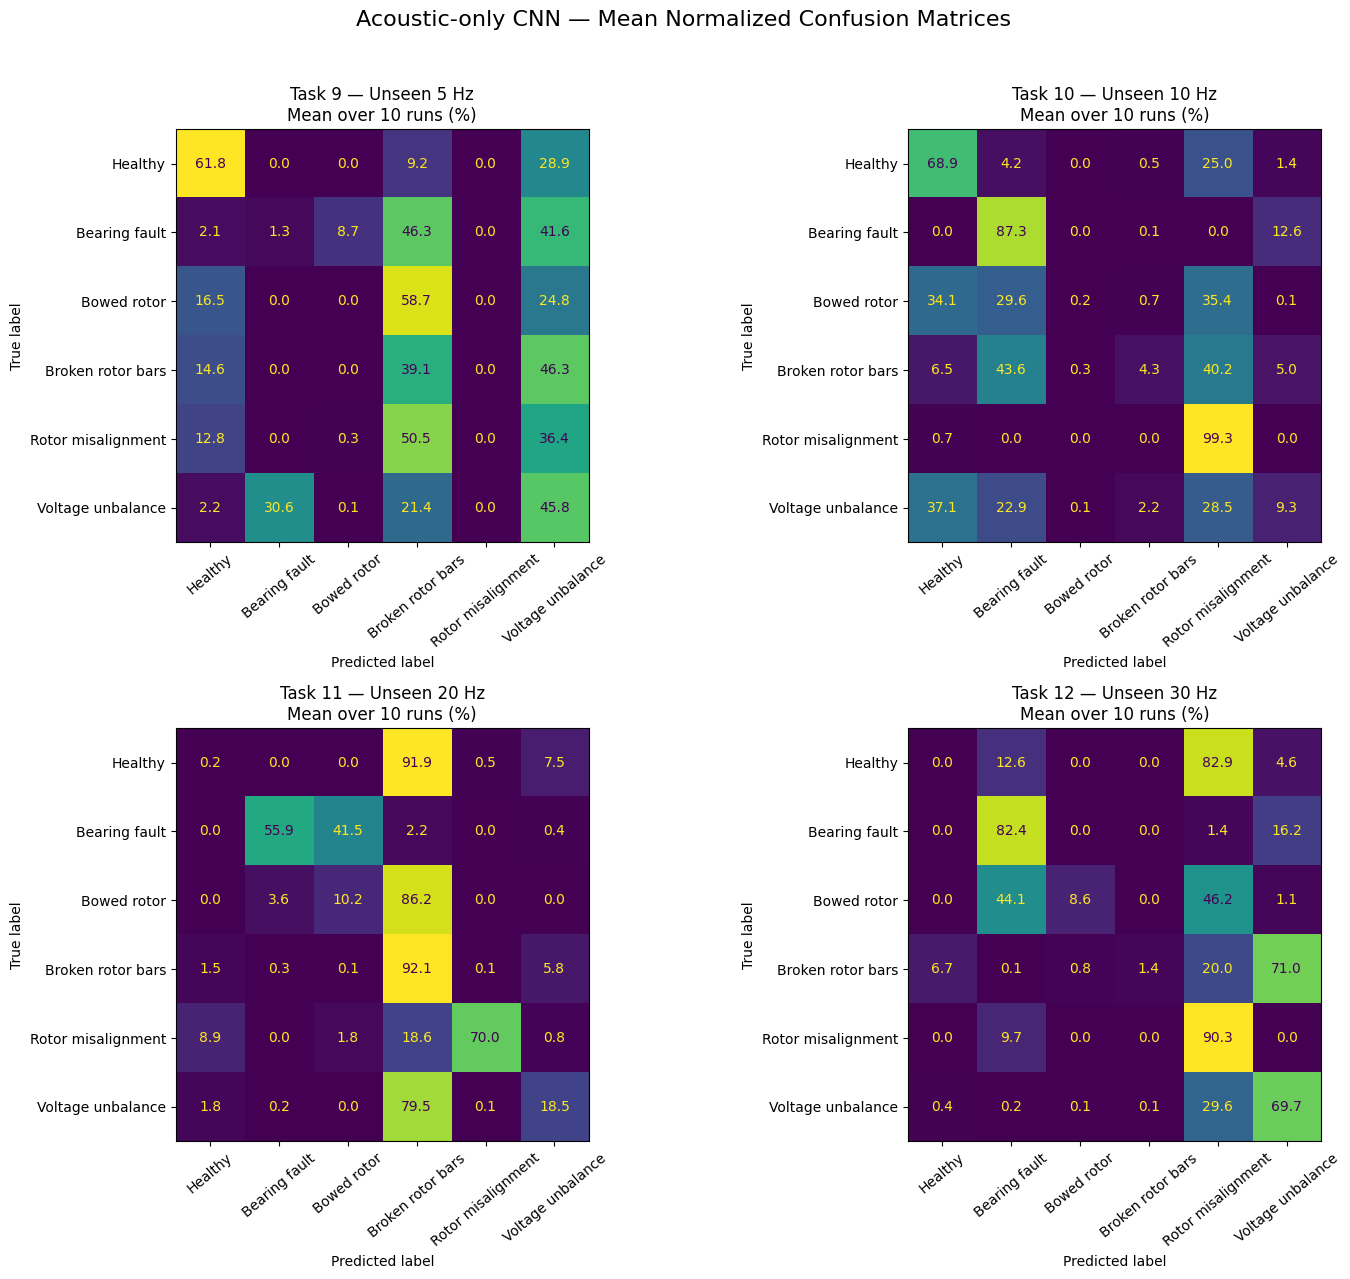

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
axes = axes.flatten()

for ax, task in zip(axes, TASKS):
    mean_cm = np.mean(confusion_matrices[task], axis=0) * 100
    ConfusionMatrixDisplay(
        mean_cm,
        display_labels=CLASS_NAMES
    ).plot(
        ax=ax,
        values_format=".1f",
        xticks_rotation=40,
        colorbar=False
    )
    ax.set_title(
        f"Task {task} — Unseen {DOMAIN_TO_SPEED[TASK_TO_DOMAIN[task]]}\n"
        "Mean over 10 runs (%)"
    )

plt.suptitle("Acoustic-only CNN — Mean Normalized Confusion Matrices", fontsize=16)
plt.tight_layout(rect=[0,0,1,0.96])
plt.savefig(
    FIGURES_DIR / "acoustic_confusion_matrices_10runs.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()


In [ ]:
task_summary = (
    task_accuracy_df
    .groupby(["task", "target_speed"])
    .agg(
        mean_accuracy=("target_accuracy", "mean"),
        std_accuracy=("target_accuracy", "std"),
        min_accuracy=("target_accuracy", "min"),
        max_accuracy=("target_accuracy", "max")
    )
    .reset_index()
)

task_summary["paper_M2"] = task_summary["task"].map(PAPER_ACOUSTIC)
task_summary["difference_pp"] = (
    task_summary["mean_accuracy"] - task_summary["paper_M2"]
)

display(task_summary)
task_summary.to_csv(
    RESULTS_DIR / "acoustic_final_comparison_10runs.csv",
    index=False
)

,task,target_speed,mean_accuracy,std_accuracy,min_accuracy,max_accuracy,paper_M2,difference_pp
0,9,5 Hz,24.675000,6.612797,15.083333,37.916667,49.23,-24.555000
1,10,10 Hz,44.883333,2.289671,41.250000,48.833333,61.89,-17.006667
2,11,20 Hz,41.141667,4.318180,36.583333,49.083333,59.14,-17.998333
3,12,30 Hz,42.041667,7.560277,29.500000,55.333333,28.13,13.911667


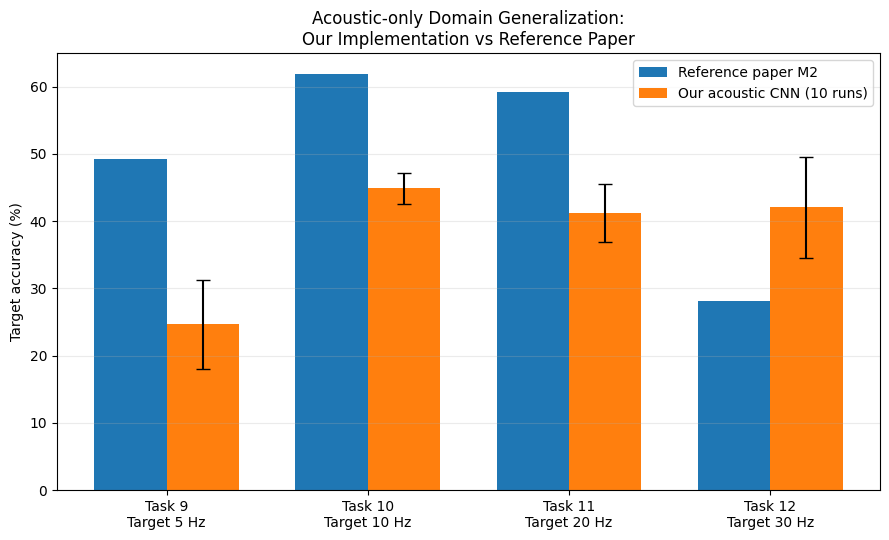

In [ ]:
tasks = task_summary["task"].to_numpy()
ours_mean = task_summary["mean_accuracy"].to_numpy()
ours_std = task_summary["std_accuracy"].to_numpy()
paper = task_summary["paper_M2"].to_numpy()

x = np.arange(len(tasks))
width = 0.36
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.bar(x - width/2, paper, width, label="Reference paper M2")
ax.bar(
    x + width/2,
    ours_mean,
    width,
    yerr=ours_std,
    capsize=5,
    label="Our acoustic CNN (10 runs)"
)
ax.set_xticks(x)
ax.set_xticklabels([
    f"Task {task}\nTarget {DOMAIN_TO_SPEED[TASK_TO_DOMAIN[task]]}"
    for task in tasks
])
ax.set_ylabel("Target accuracy (%)")
ax.set_title("Acoustic-only Domain Generalization:\nOur Implementation vs Reference Paper")
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "acoustic_paper_vs_ours_10runs.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()

In [ ]:
seed_overall = task_accuracy_df.groupby("seed")["target_accuracy"].mean()
overall_mean = seed_overall.mean()
overall_std = seed_overall.std()

print(
    f"Overall acoustic accuracy across Tasks 9–12: "
    f"{overall_mean:.2f}% ± {overall_std:.2f}%"
)
print("Reference paper M2 average: 49.60%")
print(f"Difference: {overall_mean - 49.60:+.2f} percentage points")

Overall acoustic accuracy across Tasks 9–12: 38.19% ± 2.34%
Reference paper M2 average: 49.60%
Difference: -11.41 percentage points


In [ ]:
task_macro_summary = (
    class_metrics_df
    .groupby(["task", "target_speed", "seed"])
    .agg(
        macro_precision=("precision", "mean"),
        macro_recall=("recall", "mean"),
        macro_f1=("f1", "mean")
    )
    .reset_index()
    .groupby(["task", "target_speed"])
    .agg(
        macro_precision_mean=("macro_precision", "mean"),
        macro_precision_std=("macro_precision", "std"),
        macro_recall_mean=("macro_recall", "mean"),
        macro_recall_std=("macro_recall", "std"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std")
    )
    .reset_index()
)

for col in task_macro_summary.columns:
    if col not in ["task", "target_speed"]:
        task_macro_summary[col] *= 100

display(task_macro_summary)
task_macro_summary.to_csv(
    RESULTS_DIR / "acoustic_task_macro_metrics_10runs.csv",
    index=False
)

,task,target_speed,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std
0,9,5 Hz,19.147118,5.981607,24.675000,6.612797,19.290876,4.920381
1,10,10 Hz,34.946529,7.985798,44.883333,2.289671,33.192269,2.875392
2,11,20 Hz,50.863968,4.456537,41.141667,4.318180,37.771212,3.896883
3,12,30 Hz,45.669913,12.130693,42.041667,7.560277,30.245670,7.927175
